# Grundbegriffe der Zeitreihen

Eine **Zeitreihe** besteht aus Beobachtungen, die in zeitlicher Reihenfolge vorliegen, zum Beispiel tägliche Verkaufszahlen eines Geschäfts.

## 1. Trend
Der **Trend** beschreibt die langfristige Entwicklung des Niveaus einer Zeitreihe. Die Werte können über längere Zeit steigen, sinken oder ungefähr gleich bleiben. Ein Trend muss nicht geradlinig sein.

**Beispiel:** Ein Geschäft wird bekannter; dadurch steigen seine täglichen Verkaufszahlen über mehrere Monate hinweg.

## 2. Saisonalität
**Saisonalität** bezeichnet ein wiederkehrendes Muster mit einer festen zeitlichen Periode. Diese muss kein Jahr sein: Auch ein Tagesrhythmus oder ein Wochenmuster ist saisonal.

**Beispiel:** Das Geschäft verkauft jede Woche an bestimmten Wochentagen mehr als an anderen. Die Periode beträgt sieben Tage.

## 3. Residuen
**Residuen** sind die Abweichungen zwischen beobachteten Werten und den Werten, die ein Modell erklärt:

$$r_t = y_t - \hat{y}_t.$$

Sie zeigen, was nach Berücksichtigung der modellierten Einflüsse übrig bleibt. Residuen können zufällige Schwankungen enthalten, aber auch Ausreißer oder systematische Muster, die das Modell noch nicht erfasst. Sie sind deshalb nicht automatisch reines Rauschen.

**Beispiel:** An einem Tag kommen unerwartet viele Kunden, obwohl Trend, Wochenmuster und Werbung bereits berücksichtigt sind.

## 4. Kovariate
Eine **Kovariate** ist eine zusätzliche beobachtete Variable, die zur Erklärung oder Vorhersage der Zielzeitreihe verwendet wird. Sie ist selbst kein Bestandteil der klassischen Zerlegung in Trend, Saisonalität und Rest; ein Modell kann aber ihren Einfluss zusätzlich berücksichtigen.

**Beispiel:** Die täglichen Werbeausgaben können mit den Verkaufszahlen zusammenhängen. Ein solcher Zusammenhang allein beweist noch keine Ursache. Für eine Vorhersage müssen zukünftige Werte der Kovariate bekannt sein, geplant werden oder selbst vorhergesagt werden.

## Codebeispiel: tägliche Verkaufszahlen
Wir erzeugen **künstliche Daten für 140 Tage**. So kennen wir die Bestandteile und können sie getrennt sichtbar machen. Unser additives Modell lautet:

$$y_t = T_t + S_t + \beta x_t + \varepsilon_t.$$

Dabei sind $T_t$ der Trend, $S_t$ das Wochenmuster, $x_t$ die Werbeausgaben und $\beta x_t$ deren modellierter Einfluss auf die Verkäufe. $\varepsilon_t$ ist der zufällige Fehler bei der Datenerzeugung.

Wir verwenden hier das bekannte Modell $\hat{y}_t = T_t + S_t + \beta x_t$. Deshalb stimmen seine Residuen mit den erzeugten Fehlern überein. Bei echten Daten kennt man diese Bestandteile nicht und muss sie schätzen; dann sind Residuen nur Schätzungen der zugrunde liegenden Fehler.

Benötigt werden **NumPy** und **Matplotlib**. Falls sie fehlen, kann man sie in einer separaten Notebook-Zelle mit `%pip install numpy matplotlib` installieren.

In [ ]:
import numpy as np

# Ein fester Startwert macht das Beispiel reproduzierbar.
rng = np.random.default_rng(42)
tage = np.arange(140)

# 1. Trend: Das Grundniveau wächst täglich um 0,3 Verkäufe.
trend = 100 + 0.3 * tage

# 2. Saisonalität: Dasselbe Muster wiederholt sich alle sieben Tage.
saisonalitaet = 12 * np.sin(2 * np.pi * tage / 7)

# 4. Kovariate: Geplante Werbeausgaben variieren von Tag zu Tag.
werbeausgaben = rng.uniform(0, 40, size=tage.size)  # Euro pro Tag
beta = 0.8  # Zusätzliche Verkäufe je Euro im künstlichen Modell
werbeeffekt = beta * werbeausgaben

# Zufällige Fehler und beobachtete Zeitreihe.
fehler = rng.normal(loc=0, scale=5, size=tage.size)
modellwerte = trend + saisonalitaet + werbeeffekt
verkaeufe = modellwerte + fehler

# 3. Residuen: Beobachtung minus Modellwert.
residuen = verkaeufe - modellwerte

print(f"Mittleres Residuum: {residuen.mean():.2f} Verkäufe")
print(f"Standardabweichung der Residuen: {residuen.std(ddof=1):.2f} Verkäufe")
# Zur Vereinfachung sind die simulierten Verkaufszahlen nicht gerundet.

Mittleres Residuum: -0.01 Verkäufe
Standardabweichung der Residuen: 5.20 Verkäufe


In [6]:
werbeausgaben


array([30.95824194, 17.55513759, 34.3439168 , 27.89472116,  3.76709392,
       39.02489407, 30.44558808, 31.44257221,  5.12454531, 18.01543752,
       14.83192097, 37.07059955, 25.7546048 , 32.91046453, 17.73656795,
        9.08954887, 22.18339148,  2.55269024, 33.10524688, 25.26657596,
       30.3235096 , 14.18103873, 38.82792098, 35.72484485, 31.13533988,
        7.78554831, 18.66884015,  1.75215063,  6.17157968, 27.32195813,
       29.79048624, 38.7003893 , 13.03301433, 14.81838824, 18.78223245,
        7.57885436,  5.19686021, 19.02819705,  9.07637396, 26.79255979,
       17.48607675, 33.30712784, 28.01060408, 12.49466566, 33.29039206,
       32.1905743 , 15.49913516, 11.53312416, 27.29982016,  5.59009934,
        7.9963281 ,  0.29449079, 31.4769751 , 26.59403426, 28.20661515,
       31.22916124, 18.35663102, 22.74964784,  5.59187993,  4.58120294,
       26.73611847, 18.84384825, 22.60944426, 30.5999543 , 25.3887328 ,
       22.14317603, 22.36828643, 12.15800392,  1.23271338, 17.46

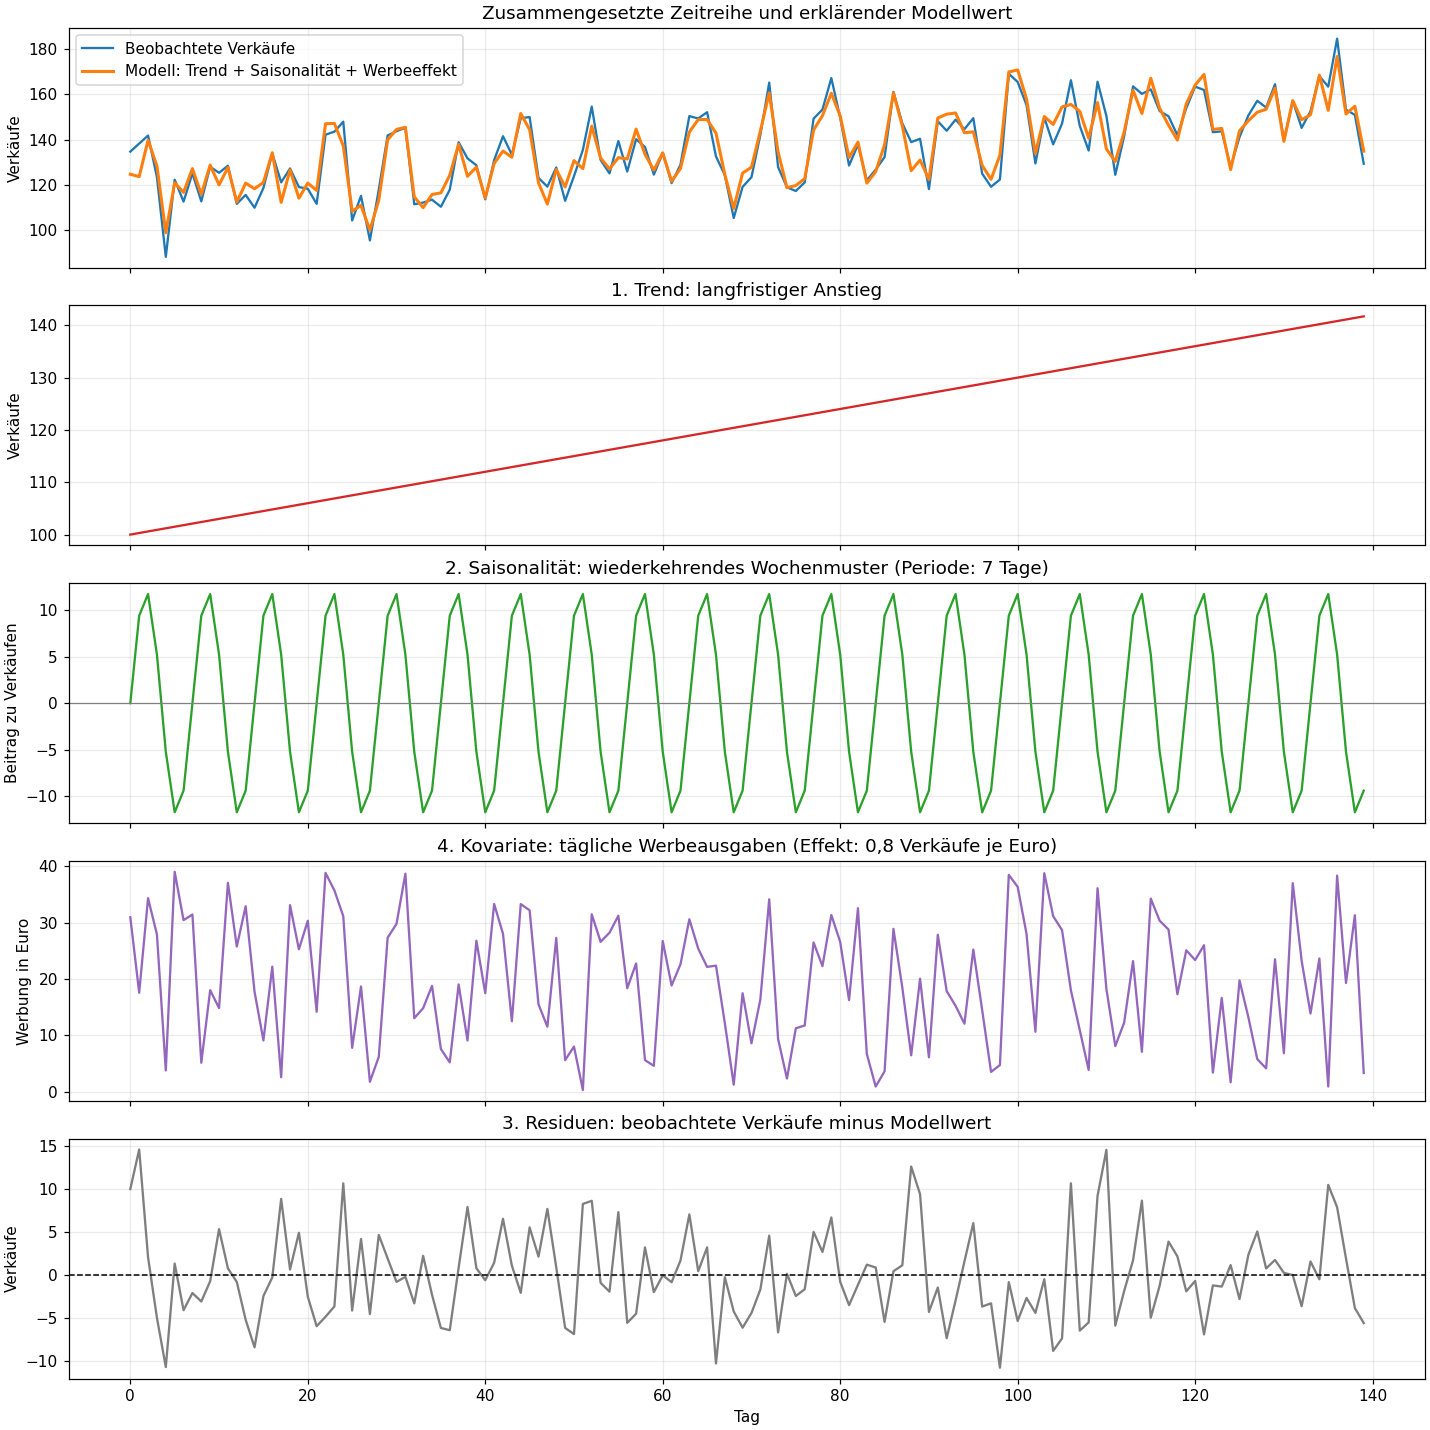

In [ ]:
import matplotlib.pyplot as plt

fig, achsen = plt.subplots(5, 1, figsize=(13, 13), sharex=True,
                          constrained_layout=True)

achsen[0].plot(tage, verkaeufe, color="tab:blue", label="Beobachtete Verkäufe")
achsen[0].plot(tage, modellwerte, color="tab:orange", linewidth=2,
               label="Modell: Trend + Saisonalität + Werbeeffekt")
achsen[0].set_title("Zusammengesetzte Zeitreihe und erklärender Modellwert")
achsen[0].set_ylabel("Verkäufe")
achsen[0].legend(loc="upper left")

achsen[1].plot(tage, trend, color="tab:red")
achsen[1].set_title("1. Trend: langfristiger Anstieg")
achsen[1].set_ylabel("Verkäufe")

achsen[2].plot(tage, saisonalitaet, color="tab:green")
achsen[2].axhline(0, color="gray", linewidth=0.8)
achsen[2].set_title("2. Saisonalität: wiederkehrendes Wochenmuster (Periode: 7 Tage)")
achsen[2].set_ylabel("Beitrag zu Verkäufen")

achsen[3].plot(tage, werbeausgaben, color="tab:purple")
achsen[3].set_title("4. Kovariate: tägliche Werbeausgaben (Effekt: 0,8 Verkäufe je Euro)")
achsen[3].set_ylabel("Werbung in Euro")

achsen[4].plot(tage, residuen, color="tab:gray")
achsen[4].axhline(0, color="black", linestyle="--", linewidth=1)
achsen[4].set_title("3. Residuen: beobachtete Verkäufe minus Modellwert")
achsen[4].set_ylabel("Verkäufe")
achsen[4].set_xlabel("Tag")

for ax in achsen:
    ax.grid(alpha=0.25)

plt.show()

### Was zeigen die Diagramme?

- **Trend:** Das Grundniveau wächst im Verlauf der 140 Tage von 100 auf knapp 142 Verkäufe pro Tag.
- **Saisonalität:** Das Wochenmuster schwankt um null und wiederholt sich alle sieben Tage. Es überlagert den Trend.
- **Kovariate:** Die Werbeausgaben variieren unabhängig vom Wochenmuster. Im konstruierten Modell erhöhen beispielsweise 20 Euro Werbung den Modellwert um 16 Verkäufe.
- **Residuen:** Die Differenzen zwischen Beobachtung und Modell schwanken um ungefähr null. Dass sie hier zufällig aussehen, ist eine Eigenschaft unserer Datenerzeugung; in echten Anwendungen muss man die Residuen darauf untersuchen.

**Zum Ausprobieren:** Ändern Sie die Trendsteigung `0.3`, die saisonale Amplitude `12`, den Werbekoeffizienten `beta` oder die Fehlerstreuung `scale=5` und führen Sie beide Codezellen erneut aus. Wie verändert sich die Zeitreihe?

# Additives und multiplikatives Zeitreihenmodell

**Additiv:** Die Bestandteile werden addiert:

$$y_t = T_t + S_t + R_t.$$

Die saisonalen Ausschläge bleiben in **absoluter Größe** ungefähr gleich: z. B. immer ±10 Verkäufe, unabhängig vom Trendniveau. Saisonkomponente und Rest schwanken typischerweise um **0**.

**Multiplikativ:** Die Bestandteile werden multipliziert:

$$y_t = T_t \cdot S_t \cdot R_t.$$

Die saisonalen Ausschläge bleiben **relativ zum Niveau** ungefähr gleich: z. B. immer ±10 %. Bei einem Trendniveau von 100 entspricht das ±10, bei 300 bereits ±30 Verkäufen. Saisonkomponente und Rest sind hier dimensionslose Faktoren um **1**; etwa bedeutet $S_t=1{,}1$ einen Aufschlag von 10 %. $R_t=y_t/(T_t S_t)$ ist der multiplikative Restfaktor.

**Faustregel:** Gleich große Ausschläge sprechen für ein additives Modell; mit dem Niveau wachsende Ausschläge für ein multiplikatives Modell. Für positive Bestandteile wird das multiplikative Modell durch Logarithmieren additiv: $\log y_t = \log T_t + \log S_t + \log R_t$.

Das Beispiel zeigt denselben steigenden Trend mit einem Wochenmuster: links ±10 Verkäufe, rechts ±10 % des Trendniveaus. Kleine zufällige Restschwankungen kommen hinzu.

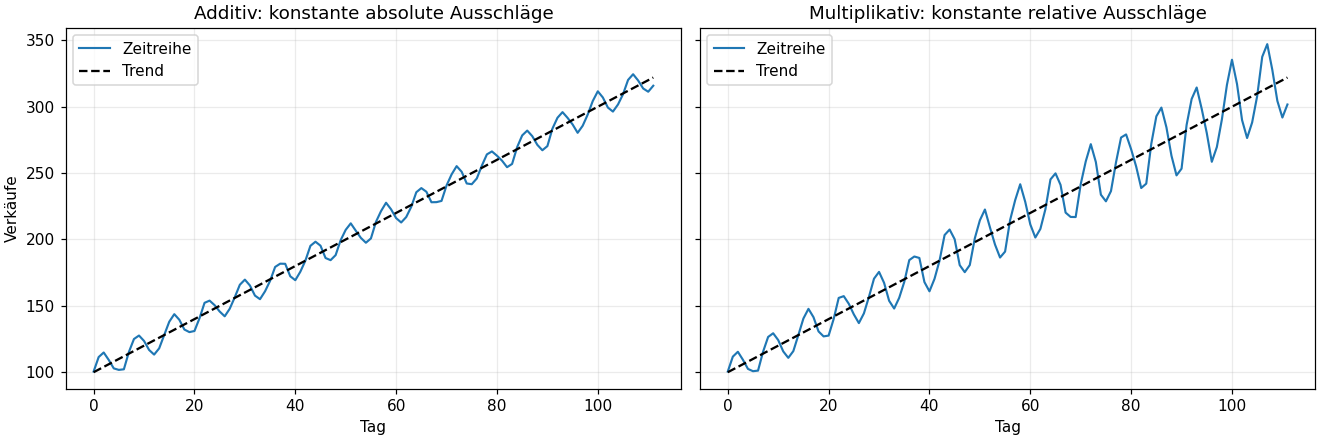

In [7]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
t = np.arange(112)
trend = 100 + 2 * t
wochenmuster = np.sin(2 * np.pi * t / 7)
zufall = rng.uniform(-1, 1, size=t.size)

# Additiv: Saisonbeitrag ±10 Verkäufe, Rest ±2 Verkäufe.
saison_add = 10 * wochenmuster
rest_add = 2 * zufall
y_add = trend + saison_add + rest_add

# Multiplikativ: Saisonfaktor 0,9 bis 1,1, Restfaktor 0,98 bis 1,02.
saison_mult = 1 + 0.10 * wochenmuster
rest_mult = 1 + 0.02 * zufall
y_mult = trend * saison_mult * rest_mult

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True,
                         constrained_layout=True)
for ax, y, titel in zip(
    axes, [y_add, y_mult],
    ["Additiv: konstante absolute Ausschläge", "Multiplikativ: konstante relative Ausschläge"]
):
    ax.plot(t, y, label="Zeitreihe", linewidth=1.4)
    ax.plot(t, trend, "k--", label="Trend")
    ax.set(title=titel, xlabel="Tag")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Verkäufe")
plt.show()

# Stationarität von Zeitreihen

Eine Zeitreihe heißt anschaulich **stationär**, wenn sich ihre statistischen Eigenschaften bei einer zeitlichen Verschiebung nicht ändern. Gemeint ist meist die **schwache Stationarität** eines zugrunde liegenden Zufallsprozesses:

- Der **Erwartungswert** bleibt konstant.
- Die **Varianz** bleibt konstant und ist endlich.
- Die **Autokovarianz** (Abhängigkeit zwischen zwei Zeitpunkten) hängt nur von deren zeitlichem Abstand ab, nicht von ihrer Lage in der Zeit.

Stationär bedeutet also nicht, dass alle Werte gleich sind! Eine stationäre Reihe darf schwanken und zeitliche Abhängigkeiten enthalten. Ein deterministischer Trend oder ein festes saisonales Muster im Mittelwert verletzt dagegen die Stationarität.

**Beispiel:** Unabhängige, normalverteilte Zufallswerte mit unverändertem Mittelwert und unveränderter Streuung bilden einen stationären Prozess. Addieren wir einen steigenden Trend, ist der Erwartungswert nicht mehr konstant: Die Reihe ist **nicht stationär**, obwohl ihre Varianz weiterhin konstant ist.

**Weiteres Gegenbeispiel:** Auch bei konstantem Erwartungswert ist eine Reihe **nicht stationär**, wenn ihre Varianz mit der Zeit steigt. Die Werte streuen dann immer stärker um dasselbe Niveau.

Viele klassische Zeitreihenmodelle setzen Stationarität voraus. Trendbereinigung, saisonale Bereinigung oder Differenzen $\Delta y_t = y_t-y_{t-1}$ können helfen, sie herzustellen. Welche Transformation geeignet ist, hängt von der Reihe ab.

## Codebeispiel: stationär, steigender Mittelwert und steigende Varianz
Alle drei Reihen verwenden dieselben standardnormalverteilten Zufallswerte. Im dritten Beispiel wächst die Standardabweichung mit $\sigma_t = 0{,}5 + 0{,}01t$; damit steigt die Varianz $\sigma_t^2$, während der Erwartungswert bei 10 bleibt.

Die orange Linie zeigt jeweils den **gleitenden Mittelwert über 30 Beobachtungen**; die gestrichelte Linie den bekannten Erwartungswert. Das graue Band markiert den Bereich Erwartungswert ± eine Standardabweichung aus der Datenerzeugung.

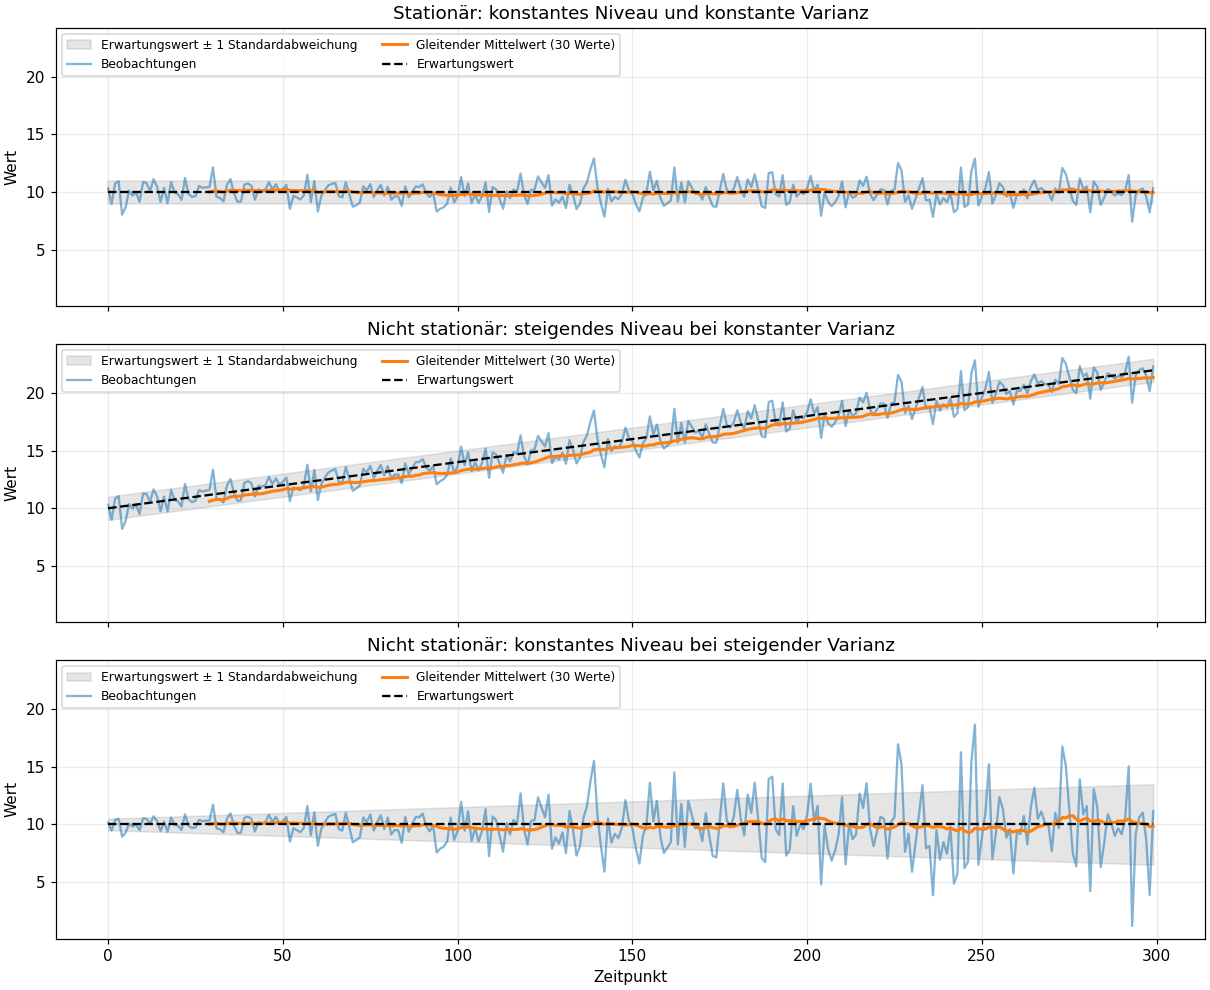

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
t = np.arange(300)
rauschen = rng.normal(loc=0, scale=1, size=t.size)

stationaer = 10 + rauschen                  # Erwartungswert 10, Varianz 1
mit_trend = 10 + 0.04 * t + rauschen         # Erwartungswert wächst, Varianz 1
sigma = 0.5 + 0.01 * t                      # Wachsende Standardabweichung
mit_wachsender_varianz = 10 + sigma * rauschen  # Erwartungswert 10, Varianz sigma²

fenster = 30
konstant = np.full(t.size, 10.0)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, y, erwartungswert, streuung, titel in zip(
    axes,
    [stationaer, mit_trend, mit_wachsender_varianz],
    [konstant, 10 + 0.04 * t, konstant],
    [np.ones(t.size), np.ones(t.size), sigma],
    ["Stationär: konstantes Niveau und konstante Varianz",
     "Nicht stationär: steigendes Niveau bei konstanter Varianz",
     "Nicht stationär: konstantes Niveau bei steigender Varianz"]
):
    mittel = np.convolve(y, np.ones(fenster) / fenster, mode="valid")
    ax.fill_between(t, erwartungswert - streuung, erwartungswert + streuung,
                    color="gray", alpha=0.2, label="Erwartungswert ± 1 Standardabweichung")
    ax.plot(t, y, alpha=0.55, label="Beobachtungen")
    ax.plot(t[fenster - 1:], mittel, color="tab:orange", linewidth=2,
            label="Gleitender Mittelwert (30 Werte)")
    ax.plot(t, erwartungswert, "k--", label="Erwartungswert")
    ax.set(title=titel, ylabel="Wert")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left", fontsize=8, ncol=2)
axes[-1].set_xlabel("Zeitpunkt")
plt.show()


**Interpretation:**

- **Oben:** Der gleitende Mittelwert schwankt um 10; die Streuung bleibt konstant. Der erzeugende Prozess ist stationär.
- **Mitte:** Der Erwartungswert steigt, während die Streuung um ihn konstant bleibt. Die Reihe ist nicht stationär.
- **Unten:** Der Erwartungswert bleibt exakt bei 10, aber die Streuung wächst. Das graue Band wird breiter. Auch diese Reihe ist nicht stationär. Der gleitende Mittelwert muss dabei nicht genau 10 sein und kann bei größerer Streuung stärker schwanken.

**Merke:** Weder ein konstanter Erwartungswert noch eine konstante Varianz allein reichen für Stationarität aus.

Ein Diagramm oder ein ungefähr konstanter gleitender Mittelwert **beweist keine Stationarität**. Hier kennen wir die Eigenschaften aufgrund der Datenerzeugung. Bei echten Daten untersucht man zusätzlich Streuung, zeitliche Abhängigkeiten und gegebenenfalls statistische Tests.


# Lag und Lag-Plots

Ein **Lag** ist ein zeitlicher Abstand in Beobachtungsschritten. Bei täglichen Daten bedeutet **Lag 1** einen Tag zurück und **Lag 7** eine Woche zurück.

Ein **Lag-Plot** stellt frühere und aktuelle Werte derselben Zeitreihe als Punkte gegenüber:

$$\text{x-Achse: } y_{t-k}, \qquad \text{y-Achse: } y_t.$$

Jeder Punkt gehört zu einem Wertepaar mit Abstand $k$. Eine aufwärts gerichtete Punktwolke zeigt: Auf hohe Werte folgen nach $k$ Schritten häufig wieder hohe Werte. Eine abwärts gerichtete Wolke deutet auf einen gegenläufigen Zusammenhang hin. Auch gekrümmte Muster sind möglich; eine ungeordnete Wolke zeigt keinen deutlichen Zusammenhang.

**Beispiel:** Wir erzeugen tägliche Werte mit einem verrauschten Wochenmuster und vergleichen alle Lags von **1 bis 10 Tagen**. Gleiche Achsengrenzen erleichtern den Vergleich der Punktwolken.

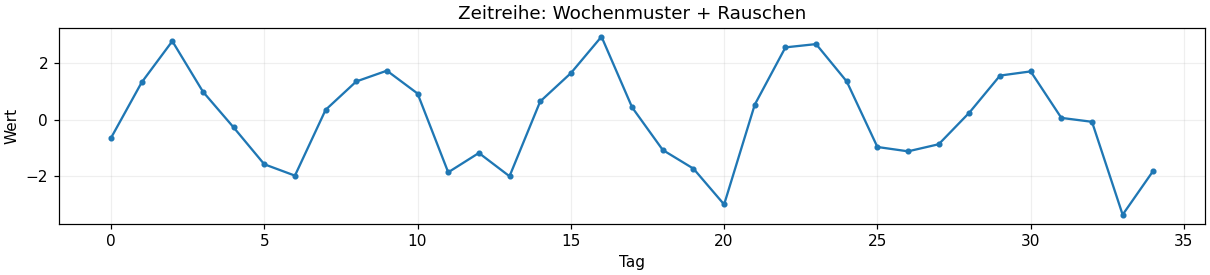

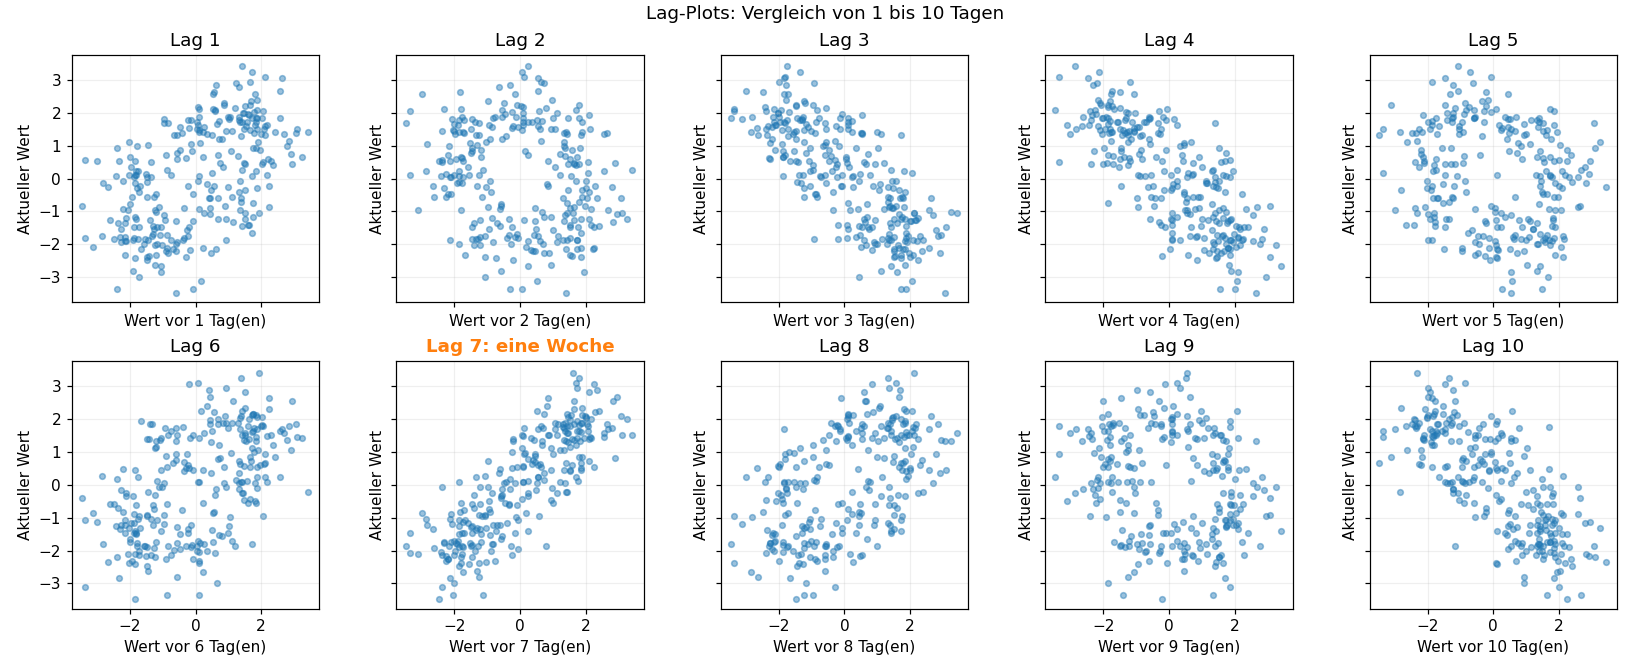

In [12]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)
tage_lag = np.arange(280)
werte_lag = (2 * np.sin(2 * np.pi * tage_lag / 7)
             + rng.normal(0, 0.65, size=tage_lag.size))

# Die Zeitreihe separat anzeigen.
fig, ax = plt.subplots(figsize=(11, 2.5), constrained_layout=True)
ax.plot(tage_lag[:35], werte_lag[:35], marker=".")
ax.set(title="Zeitreihe: Wochenmuster + Rauschen", xlabel="Tag", ylabel="Wert")
ax.grid(alpha=0.2)
plt.show()

# Lag 1 bis Lag 10: identische Achsenskalierung für alle Diagramme.
fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharex=True, sharey=True,
                         constrained_layout=True)
grenze = np.max(np.abs(werte_lag)) + 0.3
for lag, ax in enumerate(axes.flat, start=1):
    ax.scatter(werte_lag[:-lag], werte_lag[lag:], s=14, alpha=0.45)
    ax.set(title=f"Lag {lag}", xlabel=f"Wert vor {lag} Tag(en)",
           ylabel="Aktueller Wert", xlim=(-grenze, grenze),
           ylim=(-grenze, grenze))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    if lag == 7:
        ax.set_title("Lag 7: eine Woche", color="tab:orange", fontweight="bold")
fig.suptitle("Lag-Plots: Vergleich von 1 bis 10 Tagen")
plt.show()


In [10]:
import numpy as np
daten = np.arange(1,51)
daten[7:]

array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
       25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41,
       42, 43, 44, 45, 46, 47, 48, 49, 50])

**Beobachtung:** Bei **Lag 7** zeigt sich die stärkste aufwärts gerichtete Punktwolke: Nach einer Woche kehrt dieselbe Phase des Musters zurück. Bei **Lag 3 und 4** ist der Zusammenhang deutlich gegenläufig, da hohe und niedrige Phasen aufeinandertreffen. Die Muster wiederholen sich ungefähr nach sieben Tagen: **Lag 8 ähnelt Lag 1**, Lag 9 ähnelt Lag 2 und Lag 10 ähnelt Lag 3. Das Rauschen verbreitert die Punktwolken.


# Autokorrelationsfunktion und Autokorrelationsplot

Die **Autokorrelationsfunktion (ACF)** ordnet jedem Lag $k$ eine Zahl zu: die lineare Korrelation zwischen einer Zeitreihe und ihrer um $k$ Schritte verschobenen Version. Für einen stationären Prozess schreibt man:

$$\rho(k) = \operatorname{Corr}(Y_t, Y_{t-k}).$$

- **Nahe +1:** Hohe Werte gehen nach $k$ Schritten häufig mit hohen Werten einher.
- **Nahe −1:** Hohe Werte gehen häufig mit niedrigen Werten einher.
- **Nahe 0:** Kaum linearer Zusammenhang; nichtlineare Abhängigkeiten sind trotzdem möglich.

Bei **Lag 0** wird eine nicht konstante Reihe mit sich selbst verglichen: Die Korrelation ist 1.

Der **Autokorrelationsplot** ist die grafische Darstellung dieser Funktion: Auf der x-Achse stehen die Lags, auf der y-Achse die geschätzten Autokorrelationen. Während ein Lag-Plot einzelne Wertepaare für einen Lag zeigt, fasst der ACF-Plot die linearen Zusammenhänge für viele Lags zusammen.

**Codebeispiel:** Wir erzeugen dasselbe Wochenmuster erneut und berechnen die ACF bis Lag 28. Dafür wird die folgende übliche Schätzung mit dem Gesamtmittelwert $\bar y$ verwendet:

$$\hat\rho(k) = \frac{\sum_{t=k}^{n-1}(y_t-\bar y)(y_{t-k}-\bar y)}{\sum_{t=0}^{n-1}(y_t-\bar y)^2}.$$

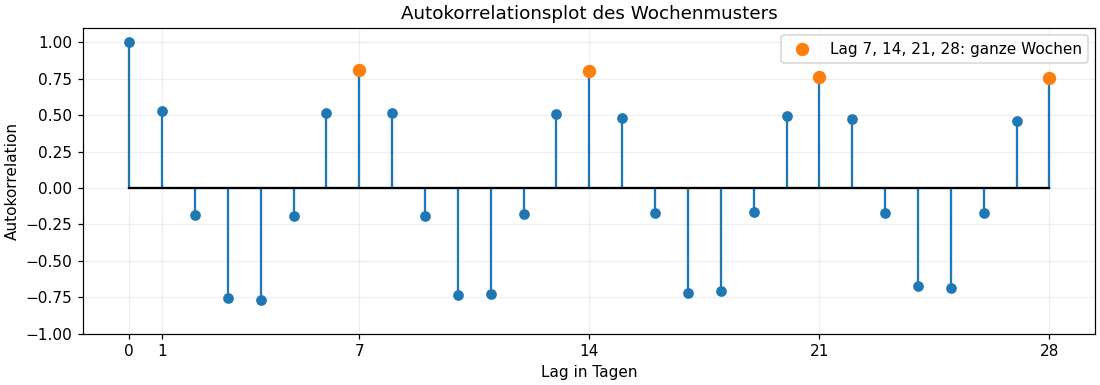

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Selbstständig ausführbar; dieselben Daten wie im Lag-Abschnitt.
rng = np.random.default_rng(123)
tage_acf = np.arange(280)
werte_acf = (2 * np.sin(2 * np.pi * tage_acf / 7)
             + rng.normal(0, 0.65, size=tage_acf.size))


def empirische_acf(werte, max_lag):
    z = np.asarray(werte, dtype=float)
    z = z - z.mean()
    nenner = np.dot(z, z)
    if nenner == 0:
        raise ValueError("Für konstante Reihen ist die ACF nicht definiert.")
    return np.array([
        np.dot(z[k:], z[:len(z) - k]) / nenner
        for k in range(max_lag + 1)
    ])


lags = np.arange(29)
acf_werte = empirische_acf(werte_acf, max_lag=28)
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
ax.stem(lags, acf_werte, basefmt="k-")
# Ganze Wochen hervorheben.
ax.scatter(lags[7::7], acf_werte[7::7], color="tab:orange", s=60,
           zorder=3, label="Lag 7, 14, 21, 28: ganze Wochen")
ax.set(title="Autokorrelationsplot des Wochenmusters", xlabel="Lag in Tagen",
       ylabel="Autokorrelation", ylim=(-1, 1.1), xticks=[0, 1, 7, 14, 21, 28])
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**Was hat die ACF mit Saisonalität zu tun?** Bei Lag **7, 14, 21 und 28** erscheinen positive Spitzen: Nach einer oder mehreren Wochen kehrt dieselbe Phase des Musters zurück. Dazwischen treten bei unserem sinusförmigen Muster negative Korrelationen auf, weil hohe und niedrige Phasen aufeinandertreffen.

Regelmäßig wiederkehrende Spitzen können also auf eine **saisonale Periode** hinweisen. Sie sind kein Beweis: Auch Trends und andere zeitliche Abhängigkeiten können starke Autokorrelation erzeugen. Deshalb sollte man gegebenenfalls zuerst den Trend entfernen. Bei endlich vielen Beobachtungen ist die ACF eine Schätzung; die Spitzen müssen nicht exakt gleich hoch sein.